<a id="chapter-14"></a>

# Chapter 14 · Web Navigation / Web 导航

[← 学习索引](../README.md) · [项目主页](../../README.md) · [跳到本章扩展](#extension)

> 学习方式：按顺序读到代码单元，先预测输出再运行。正文只保留理解主线；非必要的证明、变体与工程细节放在[扩展](#extension)。

**学完本章，你应该能：**

- 定义网页观测与点击动作
- 理解 demonstrations 与 action discretization
- 识别自动化环境的安全边界

**开始前最好已经会：**

- 理解 Gym 环境和图像/DOM 观测
- 了解行为克隆
- 会处理二维坐标


## 原书覆盖地图

| 原书主题 | 本 notebook 对应位置 | 深度 |
|---|---|---|
| Evolution / browser automation / challenges | 问题建模与安全边界 | 详细 |
| MiniWoB / MiniWoB++ | 环境接口与源码路线 | 详细 |
| Simple clicking approach | 坐标离散与模型 | 完整 |
| Adding text description | 多模态输入 | 详细 |
| Human demonstrations | 行为克隆推导与数据 | 详细 |
| Things to try | 练习与扩展 | 实践 |

“详细”表示正文包含推导或完整数据流；“源码路线”表示正文解释职责并链接真实实现；次要变体保留在扩展区。这样可以明确看到本章没有把原书哪个主题悄悄跳过。


## 0. 先想一个问题

网页按钮的位置、大小和 DOM 会变化，奖励又常常只在任务完成时出现。智能体怎样从少量演示学会第一步？

> 不必立刻回答。读完本章后再回到这里，尝试用两三句话作答。


## 1. 心智模型：先知道信息怎样流动

网页任务可用截图、DOM 特征或两者作为观测；动作可离散为元素选择，也可连续表示坐标。演示数据能在稀疏奖励前提供起点。

学习时始终追问三件事：**当前已知什么？要估计什么？哪个量会被更新？** 这比先背算法名称更重要。


## 2. 符号表：先统一语言

| 符号/名称 | 含义 | 阅读时怎么想 |
|---|---|---|
| $s$ | 截图、DOM 或融合观测 | 只能来自授权 sandbox 页面 |
| $a$ | 点击/输入/滚动动作 | 可按元素或坐标定义 |
| $D$ | 演示数据集 | 人类或脚本产生的 $(s,a)$ |
| $L_{BC}$ | 行为克隆损失 | 模仿演示动作 |
| viewport | 浏览器可视区域 | 坐标归一化的基准 |

第一次阅读只需认识这些符号；看到公式时再回来查，不要求一次背完。


## 3. 分步推导：公式不是凭空出现的


### 1. 行为克隆就是动作的最大似然

给定演示 $D=\{(s_i,a_i)\}$，最大化演示动作概率：

$$\max_\theta\prod_i\pi_\theta(a_i|s_i)$$

取负对数得到分类或连续回归形式的行为克隆 loss：

$$L_{BC}=-\frac1N\sum_i\log\pi_\theta(a_i|s_i)$$

它提供稀疏奖励之前的合理初始策略，但只覆盖演示访问过的状态。

### 2. covariate shift 为什么会累积错误

执行时，策略的一个小错误会进入演示中没出现过的页面状态；在那里预测更差，又导致更大偏移。因此常结合 DAgger 式重新标注或 RL 微调。

### 3. 坐标离散化

对于宽 $W$、高 $H$ 的页面和 $C\times R$ 网格：

$$col=\left\lfloor xC/W\right\rfloor,\quad row=\left\lfloor yR/H\right\rfloor$$

动作编号为 $a=row\cdot C+col$。反解使用格子中心能减少边界歧义。分辨率越高，定位越准，但动作空间更大、探索更难。


## 4. 手算一个最小例子


页面 $800\times600$，网格 $8\times6$，点击 $(420,180)$：

- `col=floor(420/800*8)=4`
- `row=floor(180/600*6)=1`
- `action=1*8+4=12`

动作 12 的格子中心为 $(450,150)$。编码后再解码不会恢复原点，而是恢复所属格子中心，这是量化误差。


> 手算的目的不是练算术，而是给公式建立可检查的直觉。代码输出与手算矛盾时，先停下来找原因。


## 5. 本章公式卡


### 行为克隆与 RL 微调

演示数据 $D=\{(s_i,a_i)\}$ 的行为克隆损失：
$$L_{BC}=-\mathbb E_{(s,a)\sim D}[\log\pi_\theta(a|s)]$$

它只学到演示分布内行为，遇到自身错误导致的新状态会累积偏差；之后可用 RL 环境奖励继续微调。


这张卡用于复习，不替代上一节的推导。


## 6. 公式 ↔ 代码逐项对照

| 数学对象/步骤 | 代码对应 | 作用与形状提示 |
|---|---|---|
| $(x,y)$ | `x, y` | 像素点击坐标 |
| $W,H$ | `width, height` | viewport 尺寸 |
| $C,R$ | `cols, rows` | 动作网格分辨率 |
| $a$ | `row * cols + col` | 二维到一维动作 id |
| 演示 $D$ | `lib/demos.py` 中的轨迹数据 | 监督预训练来源 |
| 环境交互 | `lib/wob.py` | 页面状态与动作执行 |

**从公式过渡到代码时：**连续点击坐标通常要映射到离散网格或候选元素。下面演示网格编码及反解。


## 7. 动手实验

运行前先做三件事：

1. 根据手算例子预测关键输出的方向或数量级；
2. 找到上一张表中的每个代码变量；
3. 运行后只改一个变量，观察结果是否符合公式。


In [1]:
def encode_click(x, y, width, height, cols=8, rows=6):
    col = min(cols - 1, int(x / width * cols))
    row = min(rows - 1, int(y / height * rows))
    return row * cols + col

def decode_click(action, width, height, cols=8, rows=6):
    row, col = divmod(action, cols)
    # 返回网格中心，减少边界点击歧义
    return ((col + 0.5) * width / cols, (row + 0.5) * height / rows)

action = encode_click(420, 180, width=800, height=600)
print("action:", action, "decoded center:", decode_click(action, 800, 600))


action: 12 decoded center: (450.0, 150.0)


### 怎样读运行结果

示例验证坐标转换，而非真实浏览器控制。先测试四角、中心和越界策略；真实项目再处理截图同步、元素变化与任务 reset。

如果结果不符合描述，先检查随机种子、终止 mask、数组 shape 和依赖版本，而不是马上调超参数。


## 8. 完整算法：把前面的零件装起来


```text
在授权 MiniWoB sandbox reset 任务
获取 screenshot + DOM/text + viewport metadata
候选动作：网格点击或元素点击
可选先用 demonstrations 做 behavior cloning
在线阶段：策略选动作 → 浏览器执行 → 等待页面稳定 → 读取 reward/termination
记录 trajectory；用 PG/A2C/DQN 微调
评估时按任务、seed、成功率和平均操作数报告
```


## 9. 第二个验证实验

第一个实验负责建立直觉；下面这个实验专门验证一个容易写错的性质。它仍然保持轻量，目的是让你能用断言判断实现是否符合公式。


In [2]:
# 检查坐标归一化能否跨 viewport 保持相对位置。
def normalize_xy(x, y, width, height):
    return x / width, y / height

def denormalize_xy(nx, ny, width, height):
    return nx * width, ny * height

n = normalize_xy(400, 300, 800, 600)
print("normalized:", n, "on 1920x1080:", denormalize_xy(*n, 1920, 1080))
assert n == (0.5, 0.5)


normalized: (0.5, 0.5) on 1920x1080: (960.0, 540.0)


## 10. 项目源码精读路线

| 文件 | 重点类/函数 | 阅读目的 |
|---|---|---|
| [`wob.py`](../../Chapter14/lib/wob.py) | 环境封装 | 浏览器 observation/action 生命周期 |
| [`model.py`](../../Chapter14/lib/model.py) | 点击模型 | 图像/文本输入与动作输出 |
| [`record_demo.py`](../../Chapter14/record_demo.py) | 演示录制 | 人类动作怎样进入数据集 |
| [`demos.py`](../../Chapter14/lib/demos.py) | 演示读取/拼接 | 行为克隆 batch |
| [`wob_click_train.py`](../../Chapter14/wob_click_train.py) | 点击训练 | 简单视觉策略 |
| [`wob_click_mm_train.py`](../../Chapter14/wob_click_mm_train.py) | 多模态训练 | 文本描述加入后的数据流 |

<details>
<summary>为什么按这个顺序读</summary>

网页状态异步变化，因此一次 step 不只是‘发点击’：还要等待 DOM/截图稳定并确认任务是否结束。精读 `wob.py` 时标出等待和异常路径。演示数据必须同时保存 viewport、observation 和动作坐标，否则回放时无法正确归一化。多模态模型要确认图像 batch 与文本 batch 来自同一页面时刻。

</details>

notebook 的实验负责隔离原理，仓库脚本负责完整环境、日志和训练。阅读时拿着第 6 节对照表寻找同一数学对象；变量名可以不同，数据语义不能不同。


## 11. 训练曲线、调参与失败复盘

**本章主诊断指标：**点击演示行为克隆的 loss 与命中率

下面的曲线来自可重复运行的微型训练，不是手工填写的数据。它用于学习“该看什么、怎样判断”；原书规模的训练应使用上一节链接的项目脚本，并同时保存配置、随机种子、环境步数和 wall-clock。

> 曲线阅读顺序：先看任务指标，再看优化指标，最后看资源指标。单次最好成绩不能代替多随机种子均值与波动。


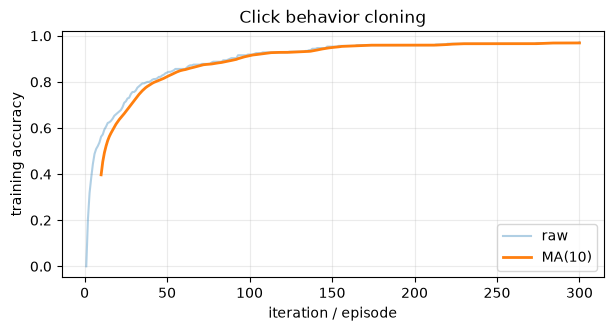

final loss/accuracy: 0.384 0.972


In [3]:
import numpy as np
import matplotlib.pyplot as plt

def plot_curve(series, title, ylabel, *, window=1):
    # Plot raw measurements and an optional moving average.
    values = np.asarray(series, dtype=float)
    x = np.arange(1, len(values) + 1)
    plt.figure(figsize=(7, 3.2))
    plt.plot(x, values, alpha=0.35, label="raw")
    if window > 1 and len(values) >= window:
        smooth = np.convolve(values, np.ones(window) / window, mode="valid")
        plt.plot(x[window - 1:], smooth, linewidth=2, label=f"MA({window})")
    plt.title(title)
    plt.xlabel("iteration / episode")
    plt.ylabel(ylabel)
    plt.grid(alpha=0.25)
    plt.legend()
    plt.show()
    plt.close()


rng = np.random.default_rng(14)
# 页面坐标 -> 4x4 点击格；RBF 模拟视觉特征，再做行为克隆。
xy = rng.random((320, 2))
labels = (np.minimum(3, (xy[:, 1] * 4).astype(int)) * 4 +
          np.minimum(3, (xy[:, 0] * 4).astype(int)))
grid = (np.arange(4) + .5) / 4
centers = np.array([(cx, cy) for cy in grid for cx in grid])
features = np.exp(-45 * ((xy[:, None, :] - centers[None, :, :]) ** 2).sum(axis=2))
x = np.c_[features, np.ones(len(features))]
w = rng.normal(0, .03, (17, 16)); losses, accuracies = [], []
for _ in range(300):
    logits = x @ w; logits -= logits.max(1, keepdims=True)
    probs = np.exp(logits); probs /= probs.sum(1, keepdims=True)
    losses.append(-np.log(probs[np.arange(len(labels)), labels] + 1e-9).mean())
    accuracies.append((logits.argmax(1) == labels).mean())
    w -= 1.2 * x.T @ (probs - np.eye(16)[labels]) / len(x)

plot_curve(accuracies, "Click behavior cloning", "training accuracy", window=10)
print("final loss/accuracy:", round(losses[-1], 3), round(accuracies[-1], 3))


### 曲线怎么读

分类准确率上升说明坐标到点击格的数据管线可学，但不能证明网页任务完成；真正评估还要记录有效点击率、页面成功率和分布外页面表现。

### 调参过程：一次只改变一个因素

- 先用演示做 behavior cloning，确认 observation/action 对齐。
- 在固定页面集调网格大小和学习率，再换未见页面评估。
- RL fine-tuning 时同时画 imitation loss 与环境 success rate，防止灾难性遗忘。

### 失败案例复盘

- 截图与动作时间戳错一帧，模型学习错误目标。
- 坐标缩放忽略浏览器 viewport，点击整体偏移。
- 只按训练页面准确率选模型，换布局后完全失效。

遇到失败时先保存配置和原始曲线，复现后再修；不要一边改环境、一边改网络、一边改学习率，否则无法知道修复来自哪里。


## 12. 实用技巧与常见坑

- 训练只应在授权的 sandbox 网站上进行。
- DOM 与截图可能异步变化，记录时间戳和页面状态。
- 点击坐标要按 viewport 尺寸归一化，否则分辨率变化会破坏策略。

这些不是附属知识：RL 结果方差大，很多“算法没学会”其实是终止语义、shape、数据泄漏或评估方式错误。


## 13. 动手练习

测试页面四个角和中心的编码/解码；说明网格分辨率与动作空间大小的权衡。

<details>
<summary>完成标准（做完再展开）</summary>

不只给出结果；还应说明改了哪个变量、对应哪条公式、变化是否符合预期，并写出至少一个边界情况。若能用 `assert` 固化结论更好。
</details>


## 14. 练习参考答案

<details>
<summary>完成练习后再展开</summary>

四角要注意右/下边界：应使用 `min(cols-1, int(...))`。中心落在中间格。网格越细量化误差越小，但动作类别数按 `rows*cols` 增长，演示和探索样本更稀疏；元素级动作能减少无效区域，但依赖 DOM 可用性。

</details>


## 15. 合上 notebook 后，脑中应留下什么

- 行为克隆提供起点，但会遭遇分布偏移。
- 动作表示决定学习难度。
- 坐标必须相对 viewport 归一化。
- 网页 RL 只能在明确授权的隔离环境运行。

回到开头的那个问题。现在请不用公式，向一个没学过本章的人解释答案；能讲清楚，才算真正理解。


## 16. 两分钟自测

**问题：**提高网格分辨率有什么好处和代价？行为克隆训练 loss 很低为何仍可能执行失败？

<details>
<summary>展开答案</summary>

更高分辨率定位更准，但动作数增多、样本更稀疏。低训练 loss 只说明拟合演示分布；策略自己的错误会进入未见状态并累积。
</details>


## 17. 与前后章节连接

第 15 章处理真正连续动作；网页坐标虽然可连续化，书中先用离散网格是为了控制探索难度。

学习强化学习最怕把算法记成孤岛。每章结束时，都应能说明本章复用了前面的什么，又为后面准备了什么。


<a id="extension"></a>

## 扩展：主线学完后再深挖

候选元素动作比固定网格更语义化；多模态策略可融合 DOM token 与截图特征，但数据管线更复杂。

扩展内容用于建立知识地图，不要求第一次学习就掌握。先确保能完成上面的两分钟自测，再决定是否继续。

[↑ 回到开头](#chapter-14) · [← 学习索引](../README.md)
